In [ ]:
import sys
import os
import numpy as np

# Add the project root (where the nn/ folder lives) to the import path
sys.path.insert(0, os.path.abspath('..'))

# Now you can import from nn
from nn import network
from nn import mnist_loader

[[0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.01 0.07 0.07 0.07 0.49 0.53 0.68 0.1  0.65 1.   0.96 0.5  0.   0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.   0.   0.12 0.14 0.37 0.6  0.66 0.99 0.99 0.99 0.99 0.99 0.88 0.67 0.99 0.95 0.76 0.25 0.   0.   0.   0.  ]

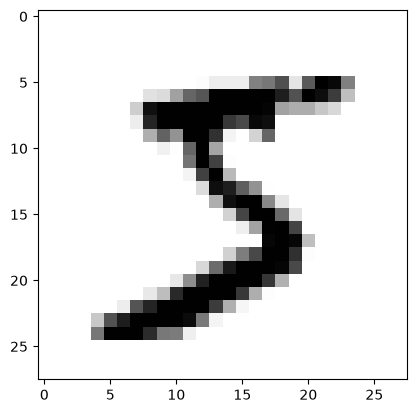

In [3]:

import matplotlib.pyplot as plt


(training_data, validation_data, test_data) = mnist_loader.load_data_wrapper("../nn/mnist.pkl.gz")
training_data = list(training_data)
validation_data = list(training_data)
test_data = list(test_data)

np.set_printoptions(linewidth=200)
plt.imshow(training_data[0][0].reshape((28,28)), cmap="gray_r")
print(training_data[0][0].round(2).reshape((28,28)))
print(darkness(training_data[0][0]))
print(training_data[0][1])

In [9]:
darknesses = [0,0,0,0,0,0,0,0,0,0]
darkcnts = [0,0,0,0,0,0,0,0,0,0]
for i in range (len(training_data)):
    x,y = training_data[i]
    digit = np.argmax(y)
    darknesses[digit] += np.sum(x)
    darkcnts[digit] += 1

print (darknesses)
print (darkcnts)

darkaverages = [darknesses[i] / darkcnts [i] for i in range(10)]
print(darkaverages)

correct = 0

for i in range (len(test_data)):
    x,y = test_data[i]
    darkx = np.sum(x)
    digit = np.argmax(y)
    diffs = [abs(darkx - darkaverages[i]) for i in range (10)]
    predicted_digit = np.argmin(diffs)
    if predicted_digit == digit:
        correct +=1

acc = correct / len(test_data)
print(acc)

[np.float32(670105.44), np.float32(338751.56), np.float32(577750.75), np.float32(565552.3), np.float32(462677.4), np.float32(452161.62), np.float32(531654.1), np.float32(465123.3), np.float32(570777.94), np.float32(479075.66)]
[4932, 5678, 4968, 5101, 4859, 4506, 4951, 5175, 4842, 4988]
[np.float32(135.86891), np.float32(59.660366), np.float32(116.29443), np.float32(110.87087), np.float32(95.2207), np.float32(100.346565), np.float32(107.38318), np.float32(89.8789), np.float32(117.880615), np.float32(96.04564)]
0.2322


In [6]:
network1_accurracies = []

net = network.Network([784, 15, 10])
for _ in range (30):
    net.SGD(training_data, 1, 20, 3.0, test_data=test_data)
    network1_accurracies.append(net.evaluate(test_data) / len(test_data))
    print(network1_accurracies)

network2_accurracies = []

net = network.Network([784, 16, 16, 10])
for _ in range (30):
    net.SGD(training_data, 1, 20, 3.0, test_data=test_data)
    network2_accurracies.append(net.evaluate(test_data) / len(test_data))
    print(network2_accurracies)

Epoch 0 : 8733 / 10000 [921/980 1121/1135]
[0.8733]
Epoch 0 : 8976 / 10000 [942/980 1106/1135]
[0.8733, 0.8976]
Epoch 0 : 9082 / 10000 [948/980 1108/1135]
[0.8733, 0.8976, 0.9082]
Epoch 0 : 9116 / 10000 [955/980 1118/1135]
[0.8733, 0.8976, 0.9082, 0.9116]
Epoch 0 : 9151 / 10000 [957/980 1112/1135]
[0.8733, 0.8976, 0.9082, 0.9116, 0.9151]
Epoch 0 : 9172 / 10000 [947/980 1112/1135]
[0.8733, 0.8976, 0.9082, 0.9116, 0.9151, 0.9172]
Epoch 0 : 9220 / 10000 [954/980 1098/1135]
[0.8733, 0.8976, 0.9082, 0.9116, 0.9151, 0.9172, 0.922]
Epoch 0 : 9231 / 10000 [945/980 1112/1135]
[0.8733, 0.8976, 0.9082, 0.9116, 0.9151, 0.9172, 0.922, 0.9231]
Epoch 0 : 9252 / 10000 [941/980 1104/1135]
[0.8733, 0.8976, 0.9082, 0.9116, 0.9151, 0.9172, 0.922, 0.9231, 0.9252]
Epoch 0 : 9259 / 10000 [945/980 1120/1135]
[0.8733, 0.8976, 0.9082, 0.9116, 0.9151, 0.9172, 0.922, 0.9231, 0.9252, 0.9259]
Epoch 0 : 9266 / 10000 [950/980 1109/1135]
[0.8733, 0.8976, 0.9082, 0.9116, 0.9151, 0.9172, 0.922, 0.9231, 0.9252, 0.9259, 0

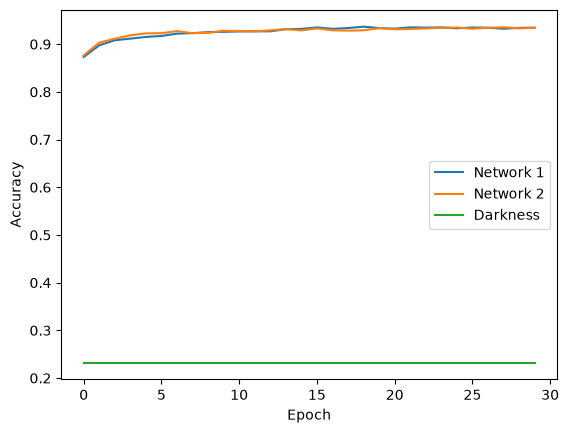

In [10]:
import matplotlib.pyplot as plt

darkaccs = [acc for _ in range (30)]

plt.plot(range(30), network1_accurracies, label='Network 1')
plt.plot(range(30), network2_accurracies, label='Network 2')
plt.plot(range(30), darkaccs, label='Darkness')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


